# Experiment 183 · Replay sources and health-aware allocation

**Complete** · Both replay comparisons complete · ETA 0h 00m 00s  
2026-11-13T22:09:34.417695+01:00 · PID 300

All arms process the same BDD100K online stream at ¼× with one singleton AdamW step per arrival. The six paired seed–mask runs, calibration checkpoints, evaluation banks, and readout positions match Experiment 182. Its saved 25% arm supplies the reference.

**Phase A.** Replay replaces every fourth arrival. Near, older, and uniform history use causal uniform draws in their eligible ranges. The older range expands to 16,384 as history accrues. Diverse replay chooses from eight candidates aged 256–2,048, using a frozen calibration encoder. It maximizes the minimum cosine distance to four preceding arrivals and earlier replay selections in the same 96-arrival block. Uniform and older sampling exclude fixed evaluation and controller anchors.

**Phase B.** The three controllers retain the reference replay source. They choose 0%, 12.5%, 25%, or 50% for each 96-arrival block, giving exactly 192 replay updates per 768 arrivals and 144 in the final 576 arrivals. Intermediate readouts inside a quota block can have unequal replay counts. Scores use only past arrivals: adjacent-embedding similarity, historical minus recent reconstruction MSE, or negative cosine between historical and recent encoder gradients. A causal percentile over the previous 32 scores proposes a fraction, and the nearest feasible fraction preserves the remaining quota. These policies use label-free training and controller signals. Scene labels enter the downstream diagnostic only. Policy time includes source selection and controller assays.

The preflight matched the saved N182 reference model and optimizer at its final checkpoint.

## Matched gains

| Phase | Policy | Arrivals | Pairs | Unseen gain | Historical gain | Incoming gain | Scene probe gain | RankMe gain | Seeds improving both |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | A | Ages 1–256 | 72,000 | 6 | -0.03054 | -0.02386 | -0.00979 | -0.77 pp | -0.58967 | 0/3 | 
 | A | Ages 2,048–16,384 | 72,000 | 6 | +0.00789 | +0.00694 | +0.00478 | -1.51 pp | -0.01491 | 2/3 | 
 | A | Uniform history | 72,000 | 6 | +0.00855 | +0.00937 | +0.00421 | -2.07 pp | -0.24558 | 3/3 | 
 | A | Embedding-diverse | 72,000 | 6 | -0.00038 | -0.00123 | +0.00512 | +0.09 pp | +0.10040 | 2/3 | 
 | B | Novelty-aware | 72,000 | 6 | +0.00210 | +0.00253 | +0.00190 | -0.34 pp | +0.14273 | 1/3 | 
 | B | Forgetting-aware | 72,000 | 6 | -0.00455 | -0.00235 | -0.00203 | -0.34 pp | -0.04088 | 1/3 | 
 | B | Gradient interference | 72,000 | 6 | -0.00661 | -0.00299 | -0.00033 | -0.34 pp | +0.05750 | 0/3 | 

Positive reconstruction gains mean lower MSE. Seed means average their matched masks and then receive equal weight. The saved JSON includes each pair and the spread across seed means.

## Progress and compute

| Phase | Seed | Mask | Policy | Updates | Replay updates | Training time | Policy time | Adaptive blocks at 0 / 12.5 / 25 / 50% |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | A | 2026 | 1 | Ages 1–256 | 72,000/72,000 | 18,000 | 0h 09m 35s | 0.0s | — | 
 | A | 2026 | 2 | Ages 1–256 | 72,000/72,000 | 18,000 | 0h 09m 19s | 0.0s | — | 
 | A | 2027 | 1 | Ages 1–256 | 72,000/72,000 | 18,000 | 0h 09m 20s | 0.0s | — | 
 | A | 2027 | 2 | Ages 1–256 | 72,000/72,000 | 18,000 | 0h 09m 20s | 0.0s | — | 
 | A | 2028 | 1 | Ages 1–256 | 72,000/72,000 | 18,000 | 0h 09m 18s | 0.0s | — | 
 | A | 2028 | 2 | Ages 1–256 | 72,000/72,000 | 18,000 | 0h 09m 18s | 0.0s | — | 
 | A | 2026 | 1 | Ages 2,048–16,384 | 72,000/72,000 | 18,000 | 0h 09m 26s | 0.0s | — | 
 | A | 2026 | 2 | Ages 2,048–16,384 | 72,000/72,000 | 18,000 | 0h 09m 21s | 0.0s | — | 
 | A | 2027 | 1 | Ages 2,048–16,384 | 72,000/72,000 | 18,000 | 0h 09m 22s | 0.0s | — | 
 | A | 2027 | 2 | Ages 2,048–16,384 | 72,000/72,000 | 18,000 | 0h 09m 24s | 0.0s | — | 
 | A | 2028 | 1 | Ages 2,048–16,384 | 72,000/72,000 | 18,000 | 0h 09m 24s | 0.0s | — | 
 | A | 2028 | 2 | Ages 2,048–16,384 | 72,000/72,000 | 18,000 | 0h 09m 20s | 0.0s | — | 
 | A | 2026 | 1 | Uniform history | 72,000/72,000 | 18,000 | 0h 09m 21s | 0.0s | — | 
 | A | 2026 | 2 | Uniform history | 72,000/72,000 | 18,000 | 0h 09m 19s | 0.0s | — | 
 | A | 2027 | 1 | Uniform history | 72,000/72,000 | 18,000 | 0h 09m 22s | 0.0s | — | 
 | A | 2027 | 2 | Uniform history | 72,000/72,000 | 18,000 | 0h 09m 17s | 0.0s | — | 
 | A | 2028 | 1 | Uniform history | 72,000/72,000 | 18,000 | 0h 09m 22s | 0.0s | — | 
 | A | 2028 | 2 | Uniform history | 72,000/72,000 | 18,000 | 0h 09m 18s | 0.0s | — | 
 | A | 2026 | 1 | Embedding-diverse | 72,000/72,000 | 18,000 | 0h 09m 22s | 18.0s | — | 
 | A | 2026 | 2 | Embedding-diverse | 72,000/72,000 | 18,000 | 0h 09m 21s | 0.4s | — | 
 | A | 2027 | 1 | Embedding-diverse | 72,000/72,000 | 18,000 | 0h 09m 24s | 6.2s | — | 
 | A | 2027 | 2 | Embedding-diverse | 72,000/72,000 | 18,000 | 0h 09m 21s | 0.4s | — | 
 | A | 2028 | 1 | Embedding-diverse | 72,000/72,000 | 18,000 | 0h 09m 25s | 7.5s | — | 
 | A | 2028 | 2 | Embedding-diverse | 72,000/72,000 | 18,000 | 0h 09m 21s | 0.4s | — | 
 | B | 2026 | 1 | Novelty-aware | 72,000/72,000 | 18,000 | 0h 09m 34s | 2.4s | 157 / 162 / 193 / 238 | 
 | B | 2026 | 2 | Novelty-aware | 72,000/72,000 | 18,000 | 0h 09m 24s | 1.9s | 155 / 156 / 206 / 233 | 
 | B | 2027 | 1 | Novelty-aware | 72,000/72,000 | 18,000 | 0h 09m 23s | 1.9s | 166 / 168 / 166 / 250 | 
 | B | 2027 | 2 | Novelty-aware | 72,000/72,000 | 18,000 | 0h 09m 26s | 1.9s | 157 / 164 / 190 / 239 | 
 | B | 2028 | 1 | Novelty-aware | 72,000/72,000 | 18,000 | 0h 09m 23s | 1.9s | 157 / 172 / 178 / 243 | 
 | B | 2028 | 2 | Novelty-aware | 72,000/72,000 | 18,000 | 0h 09m 23s | 1.9s | 153 / 172 / 186 / 239 | 
 | B | 2026 | 1 | Forgetting-aware | 72,000/72,000 | 18,000 | 0h 09m 27s | 5.2s | 148 / 170 / 199 / 233 | 
 | B | 2026 | 2 | Forgetting-aware | 72,000/72,000 | 18,000 | 0h 09m 28s | 5.2s | 150 / 180 / 180 / 240 | 
 | B | 2027 | 1 | Forgetting-aware | 72,000/72,000 | 18,000 | 0h 09m 25s | 5.2s | 162 / 166 / 177 / 245 | 
 | B | 2027 | 2 | Forgetting-aware | 72,000/72,000 | 18,000 | 0h 09m 26s | 5.2s | 155 / 170 / 185 / 240 | 
 | B | 2028 | 1 | Forgetting-aware | 72,000/72,000 | 18,000 | 0h 09m 23s | 5.2s | 150 / 170 / 195 / 235 | 
 | B | 2028 | 2 | Forgetting-aware | 72,000/72,000 | 18,000 | 0h 09m 23s | 5.2s | 159 / 164 / 186 / 241 | 
 | B | 2026 | 1 | Gradient interference | 72,000/72,000 | 18,000 | 0h 09m 27s | 13.2s | 147 / 178 / 189 / 236 | 
 | B | 2026 | 2 | Gradient interference | 72,000/72,000 | 18,000 | 0h 09m 27s | 13.0s | 167 / 162 / 173 / 248 | 
 | B | 2027 | 1 | Gradient interference | 72,000/72,000 | 18,000 | 0h 09m 23s | 13.0s | 157 / 162 / 193 / 238 | 
 | B | 2027 | 2 | Gradient interference | 72,000/72,000 | 18,000 | 0h 09m 23s | 13.0s | 164 / 152 / 194 / 240 | 
 | B | 2028 | 1 | Gradient interference | 72,000/72,000 | 18,000 | 0h 09m 25s | 13.0s | 154 / 164 / 196 / 236 | 
 | B | 2028 | 2 | Gradient interference | 72,000/72,000 | 18,000 | 0h 09m 25s | 13.0s | 152 / 164 / 200 / 234 | 

In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-replay-allocation')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


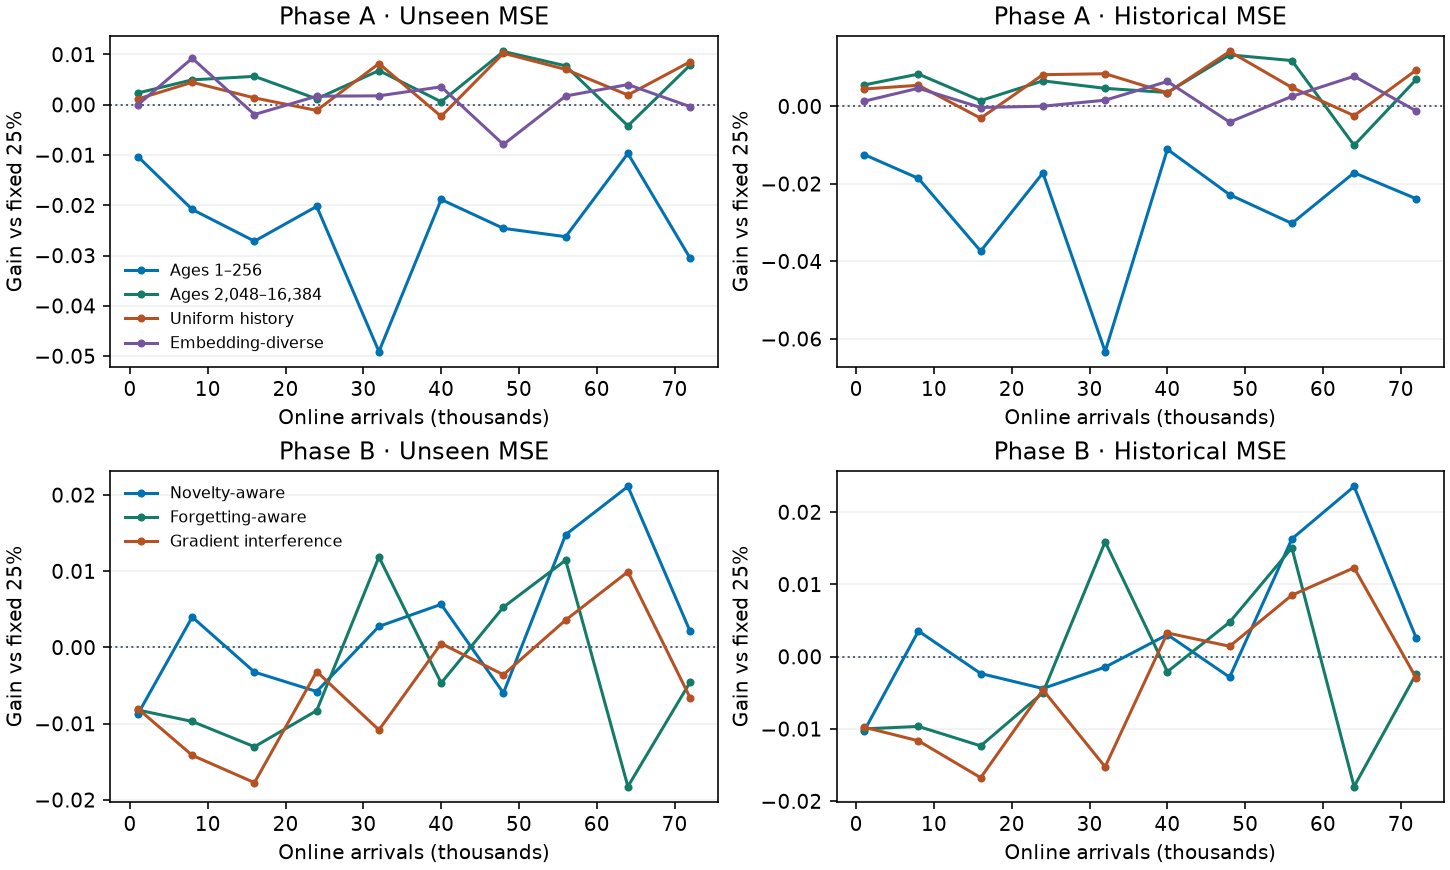